In [124]:
pip install --upgrade numpy scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [125]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.font_manager import weight_dict
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline                # chain scaler + model so scaling is learned only on training folds
from sklearn.linear_model import LogisticRegression, Lasso, Ridge, ElasticNet #linear regression models for comparison
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve, auc, ConfusionMatrixDisplay
import os                                            # create folders for saved figures

os.makedirs("figs", exist_ok=True)                   # folder where figures are saved for the report
def save(name):                                      # helper: save current figure then display it
    plt.tight_layout()                               # avoid overlapping labels
    plt.savefig(f"figs/{name}.png", dpi=130)         # write the figure to disk
    plt.show()

### 1. Data Preprocessing & Exploratory Data Analysis (EDA)

In [126]:
# Load the dataset and inspect a few rows
df = pd.read_csv("Realistic_Stock_Market_Dataset.csv")
df

,Open_Price,High_Price,Low_Price,Volume,Market_Sentiment,Interest_Rate,Inflation_Rate,GDP_Growth,Oil_Price,Gold_Price,Close_Price
0,99.176030,104.546566,97.016172,1.000001e+06,1.006315,3.086631,2.605131,2.929791,69.068106,1800.666316,105.725136
1,100.778315,105.411767,98.600014,9.999986e+05,1.274085,2.057601,2.165170,2.187336,71.323505,1800.797173,107.860104
2,98.888300,103.522518,97.240903,9.999984e+05,-0.204798,3.425928,2.630862,1.841626,71.130480,1800.495462,101.238344
3,101.156102,107.020340,98.870404,9.999992e+05,-0.794873,4.027844,3.453573,2.851414,69.332596,1798.485364,98.884042
4,99.820394,104.021392,97.312928,9.999988e+05,0.724163,2.722887,2.786708,1.848101,69.869411,1799.849017,105.929235
...,...,...,...,...,...,...,...,...,...,...,...
99995,100.755561,105.730579,97.905738,1.000000e+06,1.874254,4.199433,4.677407,5.289313,68.536784,1799.380417,110.350274
99996,101.195596,106.258506,98.932434,1.000001e+06,0.925095,3.316500,1.917595,3.490490,70.732601,1800.551027,104.461676
99997,99.933000,105.270703,97.435553,1.000000e+06,-0.129087,3.628861,2.019553,1.020607,69.049465,1799.088134,99.842150
99998,99.093338,104.159104,97.698670,1.000001e+06,0.778923,2.641889,1.535829,1.557265,69.937576,1800.651896,103.713963


In [127]:
print(f"First a few rows:\n", df.head())

First a few rows:
    Open_Price  High_Price  Low_Price        Volume  Market_Sentiment  \
0   99.176030  104.546566  97.016172  1.000001e+06          1.006315   
1  100.778315  105.411767  98.600014  9.999986e+05          1.274085   
2   98.888300  103.522518  97.240903  9.999984e+05         -0.204798   
3  101.156102  107.020340  98.870404  9.999992e+05         -0.794873   
4   99.820394  104.021392  97.312928  9.999988e+05          0.724163   

   Interest_Rate  Inflation_Rate  GDP_Growth  Oil_Price   Gold_Price  \
0       3.086631        2.605131    2.929791  69.068106  1800.666316   
1       2.057601        2.165170    2.187336  71.323505  1800.797173   
2       3.425928        2.630862    1.841626  71.130480  1800.495462   
3       4.027844        3.453573    2.851414  69.332596  1798.485364   
4       2.722887        2.786708    1.848101  69.869411  1799.849017   

   Close_Price  
0   105.725136  
1   107.860104  
2   101.238344  
3    98.884042  
4   105.929235  


In [128]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Open_Price        100000 non-null  float64
 1   High_Price        100000 non-null  float64
 2   Low_Price         100000 non-null  float64
 3   Volume            100000 non-null  float64
 4   Market_Sentiment  100000 non-null  float64
 5   Interest_Rate     100000 non-null  float64
 6   Inflation_Rate    100000 non-null  float64
 7   GDP_Growth        100000 non-null  float64
 8   Oil_Price         100000 non-null  float64
 9   Gold_Price        100000 non-null  float64
 10  Close_Price       100000 non-null  float64
dtypes: float64(11)
memory usage: 8.4 MB


In [129]:
df.describe()

,Open_Price,High_Price,Low_Price,Volume,Market_Sentiment,Interest_Rate,Inflation_Rate,GDP_Growth,Oil_Price,Gold_Price,Close_Price
count,100000.000000,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,100.004017,105.002269,98.005543,1.000000e+06,0.493256,2.999459,2.001002,2.494700,69.999200,1799.995594,103.571812
std,1.003038,1.047205,1.001586,1.005249e+00,1.000668,1.030745,1.027206,1.047860,1.008950,1.043579,5.758496
min,95.993641,100.610915,93.955256,9.999956e+05,-4.347725,-1.479091,-1.891932,-1.951419,65.656481,1795.497465,78.484278
25%,99.329134,104.299274,97.329511,9.999993e+05,-0.180215,2.302235,1.302227,1.784410,69.322260,1799.293608,99.686839
50%,100.003513,105.004416,98.003807,1.000000e+06,0.492201,2.996717,2.003141,2.497752,69.997652,1799.996069,103.570953
75%,100.679962,105.706431,98.683882,1.000001e+06,1.163523,3.694637,2.699465,3.202451,70.680927,1800.699423,107.455352
max,104.047003,109.744126,101.982937,1.000004e+06,4.777424,7.590972,6.686270,6.853010,74.669788,1804.587654,130.801777


In [130]:
print("Missing values per column:\n", df.isnull().sum())

Missing values per column:
 Open_Price          0
High_Price          0
Low_Price           0
Volume              0
Market_Sentiment    0
Interest_Rate       0
Inflation_Rate      0
GDP_Growth          0
Oil_Price           0
Gold_Price          0
Close_Price         0
dtype: int64


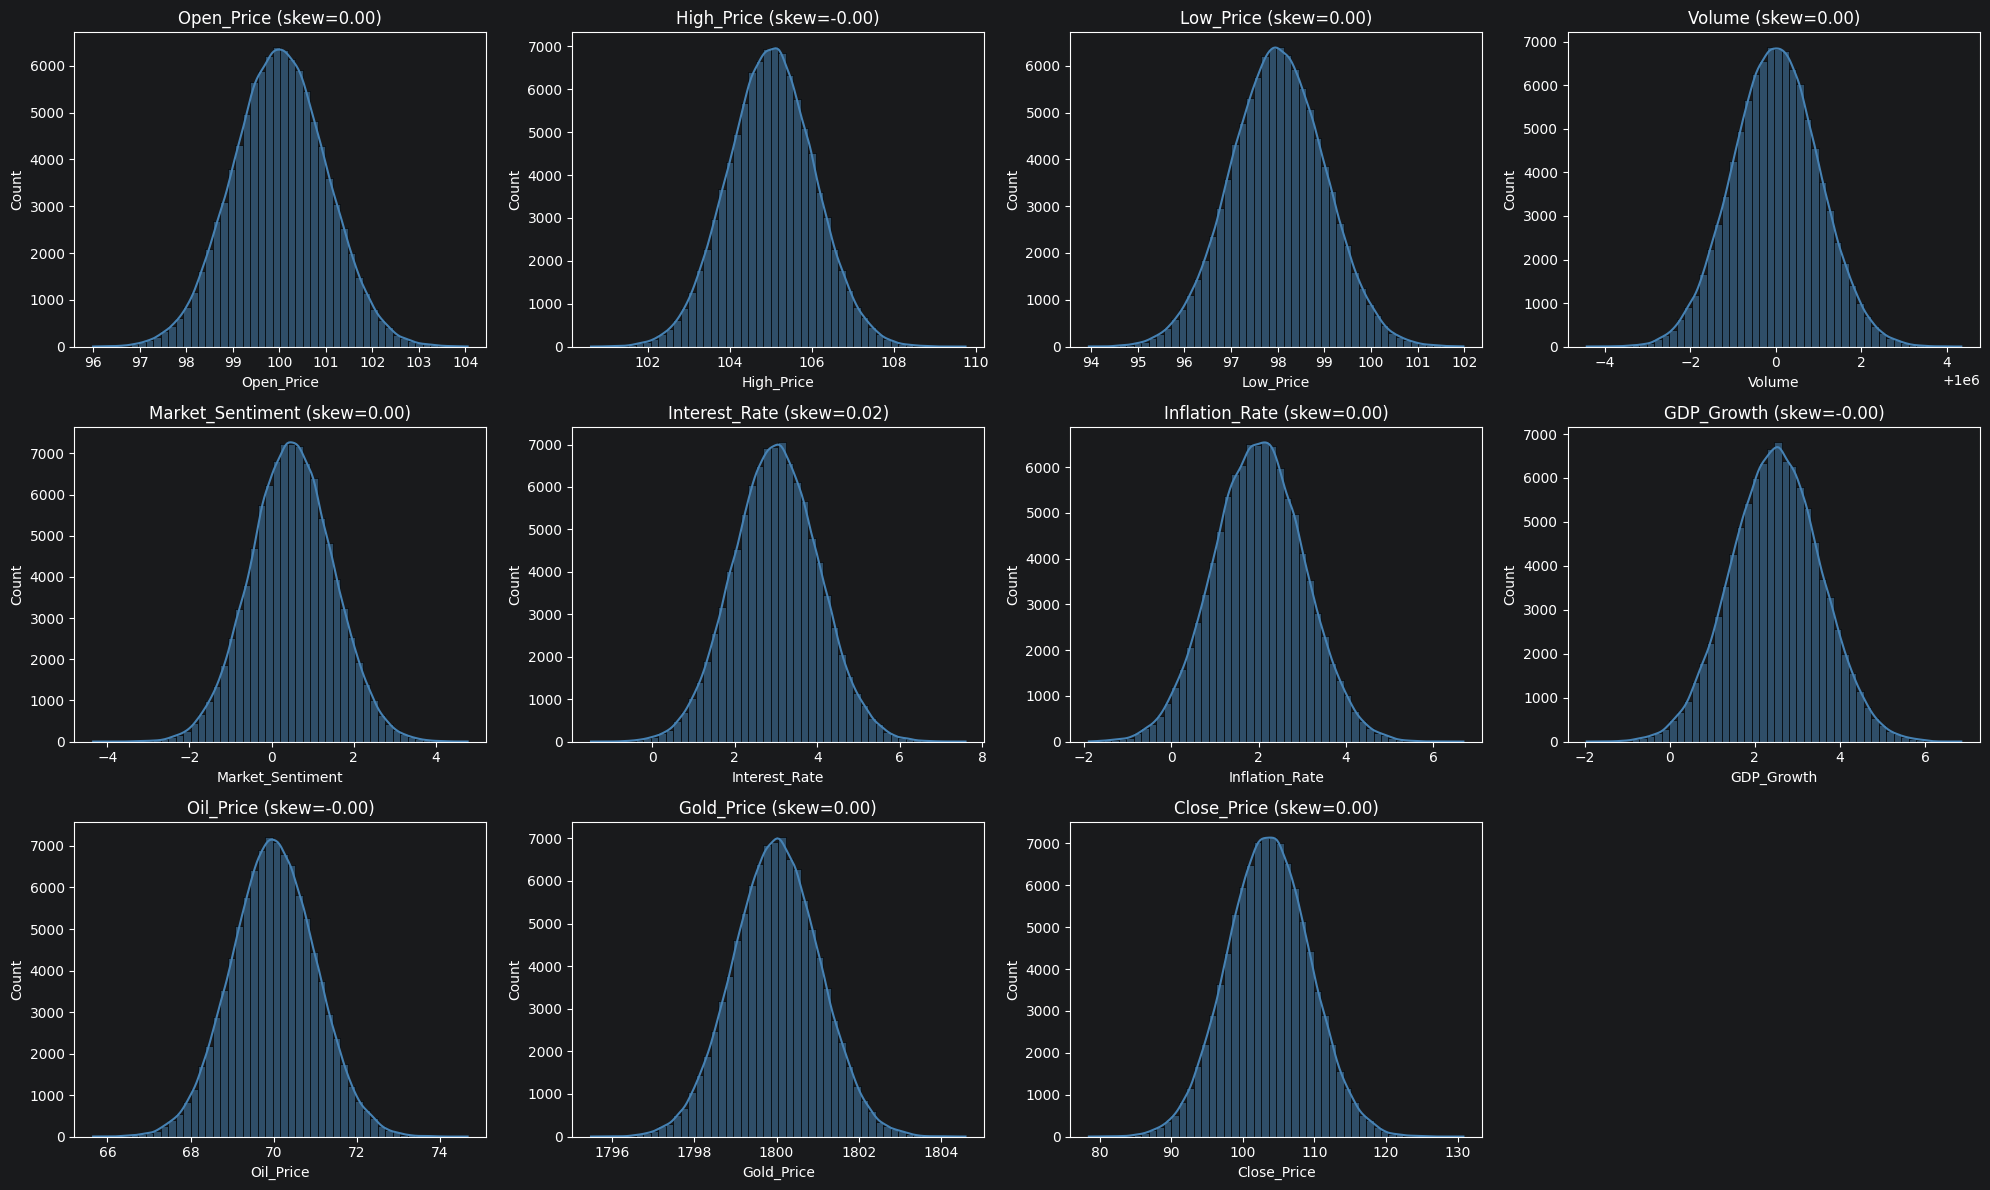

Skewness:
 Open_Price          0.002
High_Price         -0.003
Low_Price           0.002
Volume              0.005
Market_Sentiment    0.003
Interest_Rate       0.016
Inflation_Rate      0.003
GDP_Growth         -0.002
Oil_Price          -0.003
Gold_Price          0.002
Close_Price         0.004


In [131]:
target = "Close_Price"
num_cols = df.select_dtypes(include=np.number).columns.tolist()

# 1. Histograms
n, ncols = len(num_cols), 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = np.array(axes).flatten()
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], bins=50, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{col} (skew={df[col].skew():.2f})")
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("histograms.png", dpi=120)
plt.show()
plt.close()
print("Skewness:\n", df[num_cols].skew().round(3).to_string())


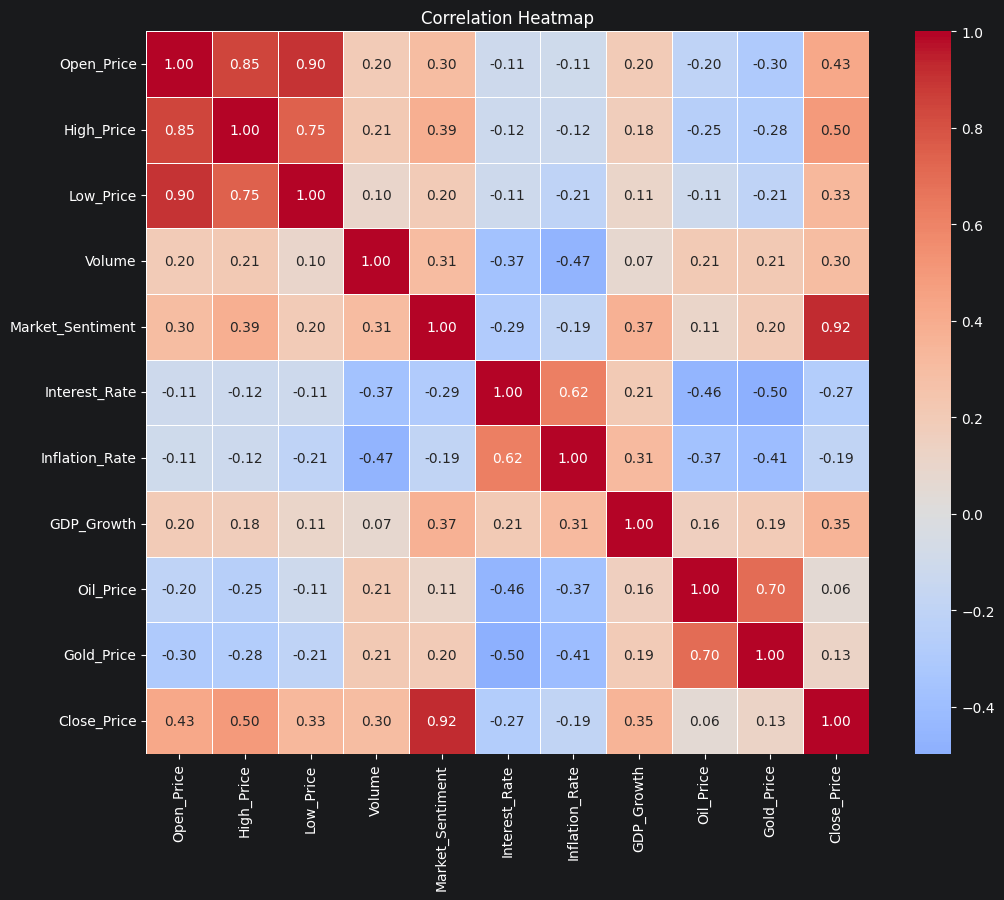


Correlation with target:
 Market_Sentiment    0.923
High_Price          0.496
Open_Price          0.426
GDP_Growth          0.351
Low_Price           0.328
Volume              0.301
Gold_Price          0.126
Oil_Price           0.057
Inflation_Rate     -0.189
Interest_Rate      -0.271

Strongest pairs (|r|>0.5):
 Market_Sentiment  Close_Price       0.923
Open_Price        Low_Price         0.901
                  High_Price        0.847
High_Price        Low_Price         0.746
Oil_Price         Gold_Price        0.701
Interest_Rate     Inflation_Rate    0.621


In [132]:
# 2. Correlation heatmap
corr = df[num_cols].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=120)
plt.show()
print("\nCorrelation with target:\n", corr[target].drop(target).sort_values(ascending=False).round(3).to_string())
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print("\nStrongest pairs (|r|>0.5):\n", pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False).round(3).to_string())

In [133]:
import joblib
# Split first, then scale (fit on train only -> no leakage)
X, y = df.drop(columns=[target]), df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)
joblib.dump(scaler, "scaler.pkl")

print("\nShapes:", X_train.shape, X_test.shape, y_train.shape, y_test.shape)
print("\nTrain scaled mean/std:\n", X_train_scaled.describe().loc[["mean", "std"]].round(3).to_string())

X_train_scaled.assign(**{target: y_train}).to_csv("train_scaled.csv", index=False)
X_test_scaled.assign(**{target: y_test}).to_csv("test_scaled.csv", index=False)




Shapes: (80000, 10) (20000, 10) (80000,) (20000,)

Train scaled mean/std:
       Open_Price  High_Price  Low_Price  Volume  Market_Sentiment  Interest_Rate  Inflation_Rate  GDP_Growth  Oil_Price  Gold_Price
mean        -0.0         0.0        0.0     0.0               0.0           -0.0             0.0         0.0        0.0         0.0
std          1.0         1.0        1.0     1.0               1.0            1.0             1.0         1.0        1.0         1.0


### STEP 2: KNN REGRESSION MODEL & TUNING
KNN predicts a price by averaging the targets of the *k* closest training rows. Distance-based, so scaling matters.

### 2.1 Tune K with GridSearchCV

In [134]:
knn_pipe = Pipeline([("scaler", StandardScaler()),         # step 1: scale inside each CV fold
                     ("knn", KNeighborsRegressor())])      # step 2: KNN regressor
knn_grid = {"knn__n_neighbors": [3, 7, 15, 31],   # candidate values of K
            "knn__weights": ["uniform", "distance"]}            # equal vs distance-weighted neighbours
knn_gs = GridSearchCV(knn_pipe, knn_grid, cv=3,                 # 3-fold cross-validation (KNN is slow on 100k rows) for every combination
                      scoring="neg_root_mean_squared_error", n_jobs=-1)   # choose by lowest RMSE, use all CPU cores
knn_gs.fit(X_train, y_train)                                    # run the search on training data
print("Best params:", knn_gs.best_params_)                      # winning K and weighting
print("Best CV RMSE:", -knn_gs.best_score_)                     # its cross-validated RMSE
best_knn = knn_gs.best_estimator_                               # refit pipeline with best params

Best params: {'knn__n_neighbors': 31, 'knn__weights': 'distance'}
Best CV RMSE: 2.2933501456497236


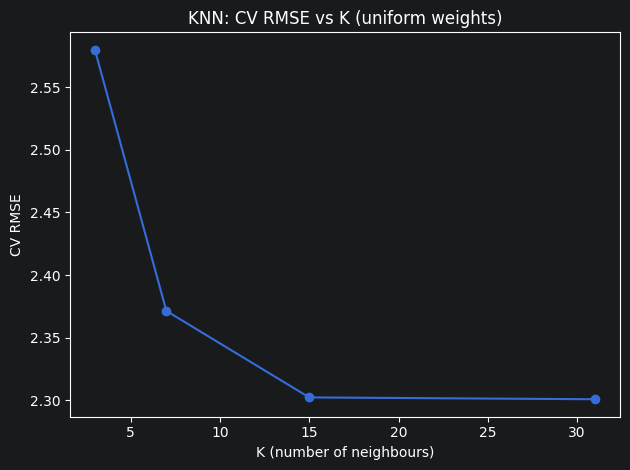

In [135]:
res = pd.DataFrame(knn_gs.cv_results_)                     # all grid-search results
res = res[res["param_knn__weights"] == "uniform"]          # keep one weighting to draw a clean curve
plt.plot(res["param_knn__n_neighbors"].astype(int), -res["mean_test_score"], marker="o")   # CV RMSE vs K
plt.xlabel("K (number of neighbours)"); plt.ylabel("CV RMSE"); plt.title("KNN: CV RMSE vs K (uniform weights)")   # labels
save("03_knn_k_curve")

### 2.2 k-fold cross-validation of the tuned model

In [136]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)   # 5 shuffled folds
cv_r2 = cross_val_score(best_knn, X_train, y_train, cv=kf, scoring="r2", n_jobs=-1)   # R2 on each fold
cv_rmse = -cross_val_score(best_knn, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)   # RMSE per fold
print(f"5-fold R2   : {cv_r2.mean():.4f} +/- {cv_r2.std():.4f}")      # average and spread of R2
print(f"5-fold RMSE : {cv_rmse.mean():.4f} +/- {cv_rmse.std():.4f}")  # average and spread of RMSE

5-fold R2   : 0.8431 +/- 0.0029
5-fold RMSE : 2.2803 +/- 0.0169


In [137]:
results = {}                                               # dictionary that will hold every model's metrics
def evaluate(name, model, Xte, yte):                       # helper to compute the four regression metrics
    pred = model.predict(Xte)                              # predictions on unseen test data
    mse = mean_squared_error(yte, pred)                    # mean squared error
    results[name] = {"MAE": mean_absolute_error(yte, pred),   # mean absolute error
                     "MSE": mse,                              # store MSE
                     "RMSE": np.sqrt(mse),                    # RMSE = square root of MSE
                     "R2": r2_score(yte, pred)}               # coefficient of determination
    return pred                                            # return predictions for plotting

knn_pred = evaluate("KNN", best_knn, X_test, y_test)       # evaluate the tuned KNN
pd.DataFrame(results).T                                    # show metrics as a table

,MAE,MSE,RMSE,R2
KNN,1.785447,5.053707,2.248045,0.847798


### 2.3 Test-set metrics and actual vs predicted

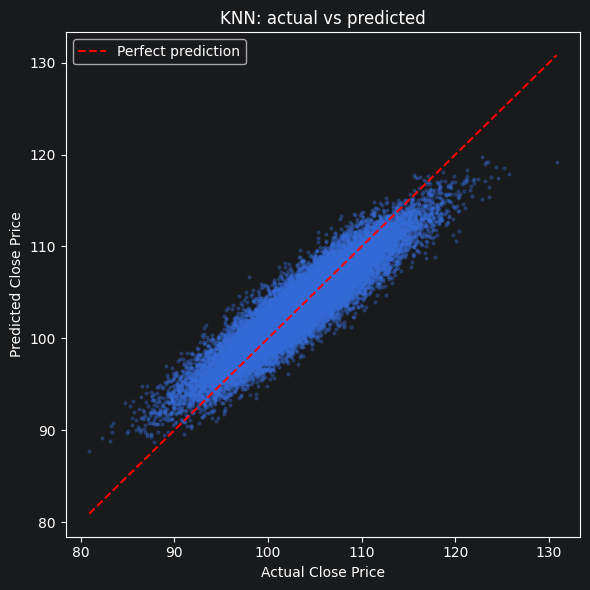

In [138]:
plt.figure(figsize=(6, 6))                                 # square figure
plt.scatter(y_test, knn_pred, s=4, alpha=0.3)              # actual (x) vs predicted (y)
lims = [y_test.min(), y_test.max()]                        # axis range
plt.plot(lims, lims, "r--", label="Perfect prediction")    # y = x reference line
plt.xlabel("Actual Close Price"); plt.ylabel("Predicted Close Price"); plt.title("KNN: actual vs predicted"); plt.legend()   # labels
save("04_knn_actual_vs_pred")                              # save + show

## 3. KNN vs Linear Regression Models (Ridge, Lasso, Elastic Net)
Regularisation shrinks coefficients: **Ridge** (L2) shrinks all, **Lasso** (L1) can set some to exactly 0, **Elastic Net** mixes both. `alpha` controls strength; `l1_ratio` the L1/L2 mix.

In [139]:
alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]           # regularisation strengths to try
configs = {                                                # model name -> (model, parameter grid)
    "Ridge": (Ridge(), {"m__alpha": alphas}),
    "Lasso": (Lasso(max_iter=20000), {"m__alpha": alphas}),
    "ElasticNet": (ElasticNet(max_iter=20000), {"m__alpha": alphas, "m__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]}),
}
fitted, preds = {}, {"KNN": knn_pred}                      # store fitted models and their predictions
for name, (model, grid) in configs.items():                # loop over the three linear models
    pipe = Pipeline([("scaler", StandardScaler()), ("m", model)])   # scale then fit
    gs = GridSearchCV(pipe, grid, cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)   # tune with 5-fold CV
    gs.fit(X_train, y_train)                               # search on training data
    fitted[name] = gs.best_estimator_                      # keep the best model
    print(name, "best params:", gs.best_params_)           # report chosen hyperparameters
    preds[name] = evaluate(name, gs.best_estimator_, X_test, y_test)   # test-set metrics
comparison = pd.DataFrame(results).T                       # table of all four models
comparison

/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/pyth

Ridge best params: {'m__alpha': 1}


/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ co

Lasso best params: {'m__alpha': 0.0001}


/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ co

ElasticNet best params: {'m__alpha': 0.0001, 'm__l1_ratio': 0.9}


/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


,MAE,MSE,RMSE,R2
KNN,1.785447,5.053707,2.248045,0.847798
Ridge,1.598427,4.003703,2.000925,0.879421
Lasso,1.598423,4.003693,2.000923,0.879421
ElasticNet,1.598423,4.003694,2.000923,0.879421


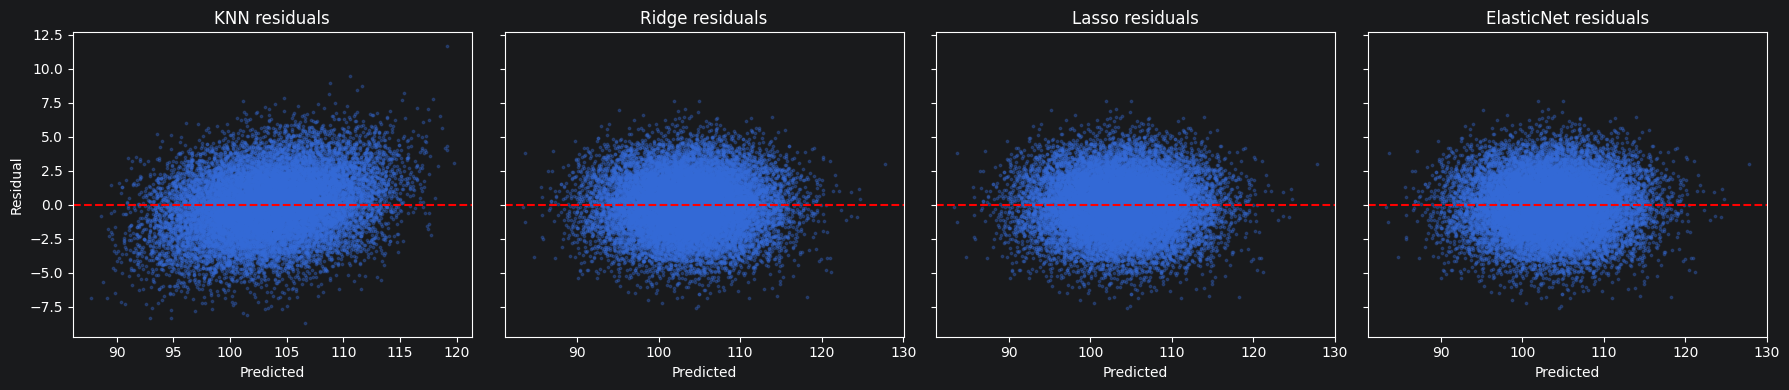

In [140]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)   # one residual plot per model
for ax, (name, p) in zip(axes, preds.items()):             # loop through predictions
    resid = y_test - p                                     # residual = actual - predicted
    ax.scatter(p, resid, s=3, alpha=0.3)                   # residuals vs predicted values
    ax.axhline(0, color="red", linestyle="--")             # zero-error line
    ax.set_title(f"{name} residuals"); ax.set_xlabel("Predicted")   # title and x label
axes[0].set_ylabel("Residual")                             # shared y label
save("05_residuals")

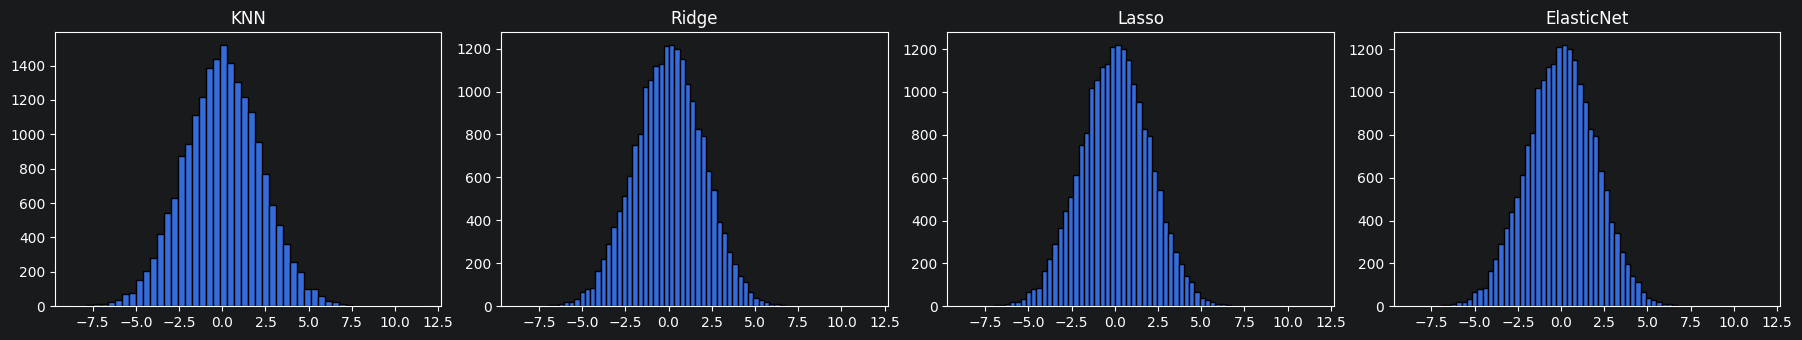

,Ridge,Lasso,ElasticNet
Open_Price,0.526,0.526,0.526
High_Price,0.338,0.338,0.338
Low_Price,0.169,0.170,0.170
Volume,-0.002,-0.002,-0.002
Market_Sentiment,5.000,5.000,5.000
Interest_Rate,0.023,0.023,0.023
Inflation_Rate,-0.008,-0.007,-0.007
GDP_Growth,-0.015,-0.014,-0.014
Oil_Price,0.009,0.009,0.009
Gold_Price,0.009,0.008,0.008


In [141]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5), sharex=True)   # residual distributions
for ax, (name, p) in zip(axes, preds.items()):             # loop through models
    ax.hist(y_test - p, bins=50, edgecolor="black")        # histogram of residuals (should be centred on 0)
    ax.set_title(f"{name}")                                # title
save("06_residual_hist")                                   # save + show
coefs = pd.DataFrame({n: fitted[n].named_steps["m"].coef_ for n in fitted}, index=X.columns)   # coefficients on scaled features
coefs.round(3)

## 4. Convert Regression to Classification
Target: **1 (Increase)** if `Close_Price > Open_Price`, else **0 (No Increase)**.
`Close_Price` is excluded from the features, since it defines the label (using it would be leakage).

In [142]:
df["Increase"] = (df["Close_Price"] > df["Open_Price"]).astype(int)   # 1 if close > open else 0
print(df["Increase"].value_counts(normalize=True))         # class balance
Xc = df.drop(columns=["Close_Price", "Increase"])          # features: drop the price and the label
yc = df["Increase"]                                        # classification target
Xc_train, Xc_test, yc_train, yc_test = train_test_split(   # stratified split keeps class ratio equal in both sets
    Xc, yc, test_size=0.2, random_state=42, stratify=yc)
clf = Pipeline([("scaler", StandardScaler()),              # scale features
                ("lr", LogisticRegression(max_iter=1000))])   # logistic regression classifier
clf.fit(Xc_train, yc_train)                                # train
yc_pred = clf.predict(Xc_test)                             # predicted classes
yc_prob = clf.predict_proba(Xc_test)[:, 1]                 # predicted probability of class 1 (for ROC)
print("Accuracy:", accuracy_score(yc_test, yc_pred))       # share of correct predictions

Increase
1    0.74523
0    0.25477
Name: proportion, dtype: float64
Accuracy: 0.90385


/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_mo

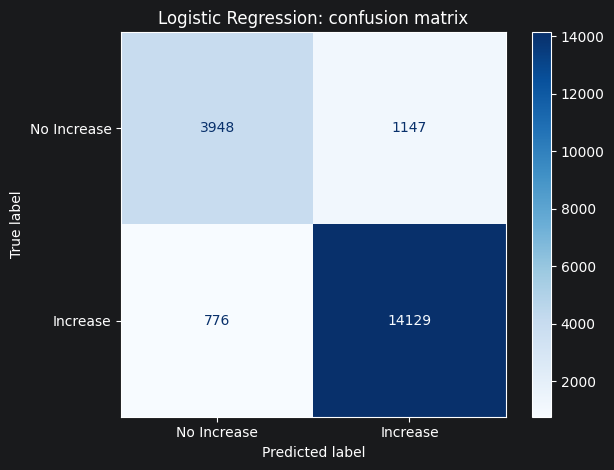

              precision    recall  f1-score   support

 No Increase       0.84      0.77      0.80      5095
    Increase       0.92      0.95      0.94     14905

    accuracy                           0.90     20000
   macro avg       0.88      0.86      0.87     20000
weighted avg       0.90      0.90      0.90     20000



In [143]:
cm = confusion_matrix(yc_test, yc_pred)                    # 2x2 matrix of TN, FP, FN, TP
ConfusionMatrixDisplay(cm, display_labels=["No Increase", "Increase"]).plot(cmap="Blues")   # draw it
plt.title("Logistic Regression: confusion matrix")         # title
save("07_confusion")                                       # save + show
print(classification_report(yc_test, yc_pred, target_names=["No Increase", "Increase"]))   # precision, recall, F1

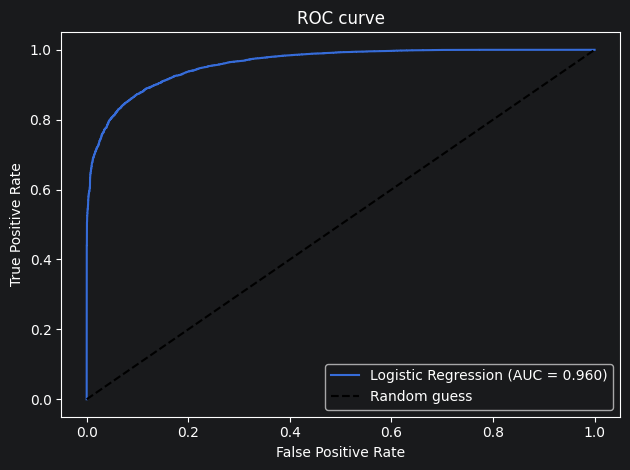

AUC: 0.9603580412287306


In [144]:
fpr, tpr, _ = roc_curve(yc_test, yc_prob)                  # false/true positive rates over thresholds
auc = roc_auc_score(yc_test, yc_prob)                      # area under the ROC curve
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")   # ROC curve
plt.plot([0, 1], [0, 1], "k--", label="Random guess")      # chance line
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC curve"); plt.legend()   # labels
save("08_roc")                                             # save + show
print("AUC:", auc)

In [145]:
# Fair comparison: turn every regression model's price prediction into a class (predicted close > open?)
open_test = X_test["Open_Price"]                           # opening prices of the regression test rows
true_cls = (y_test > open_test).astype(int)                # true class for those rows
cmp = {}                                                   # accuracy per model
for name, p in preds.items():                              # loop through regression models
    cmp[name] = accuracy_score(true_cls, (p > open_test).astype(int))   # accuracy of the derived classification
cmp["Logistic Regression"] = accuracy_score(yc_test, yc_pred)           # the dedicated classifier
pd.Series(cmp, name="Accuracy").to_frame()

,Accuracy
KNN,0.89400
Ridge,0.90080
Lasso,0.90080
ElasticNet,0.90080
Logistic Regression,0.90385


## 5. Model Comparison and Insights

In [146]:
summary = pd.DataFrame(results).T.round(4)                 # regression metrics for all models
summary["Directional accuracy"] = pd.Series(cmp).round(4)  # add the up/down accuracy
summary.loc["Logistic Regression", "Directional accuracy"] = round(cmp["Logistic Regression"], 4)
summary

,MAE,MSE,RMSE,R2,Directional accuracy
KNN,1.7854,5.0537,2.2480,0.8478,0.8940
Ridge,1.5984,4.0037,2.0009,0.8794,0.9008
Lasso,1.5984,4.0037,2.0009,0.8794,0.9008
ElasticNet,1.5984,4.0037,2.0009,0.8794,0.9008
Logistic Regression,NaN,NaN,NaN,NaN,0.9039


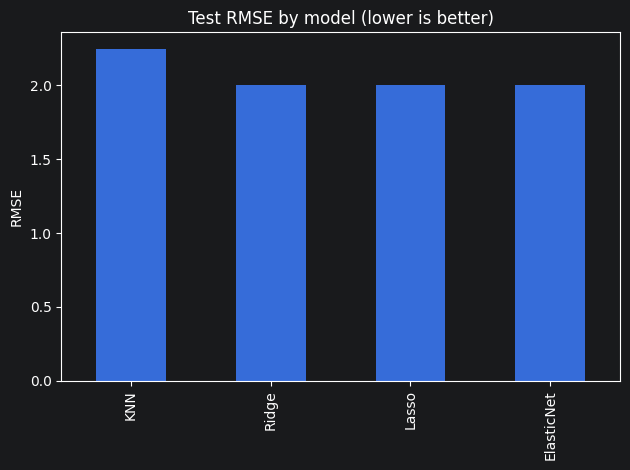

In [147]:
summary[["RMSE"]].dropna().plot.bar(legend=False, title="Test RMSE by model (lower is better)")   # bar chart of RMSE
plt.ylabel("RMSE")                                         # axis label
save("09_model_rmse")